# Final Project 

**Author**: Ashley Luo (NetID: jiayinl5)



## 1. Introduction and Background

### Introduction

**Research question:** Can neural population activity in mouse primary visual cortex (VISp) be used to decode visual grating orientation?

**Hypothesis:** Different visual grating orientations evoke distinguishable neural population responses in VISp, allowing a classifier to predict stimulus orientation above chance.



### Data source
> Siegle, J. H., Jia, X., Durand, S., et al. (2021). Survey of spiking in the mouse visual system reveals functional hierarchy. *Nature*, *592*, 86–92. https://doi.org/10.1038/s41586-020-03171-x

**Dataset:** Allen Brain Observatory *Visual Coding – Neuropixels*, **session 715093703**, trimmed for this course (download `allen_715093703_visual_units.nwb` from the class Box folder). Free for research and education under the Allen Institute Terms of Use, with citation.

**What is in the file:** 611 sorted units from visual cortex (VISp and higher areas), the LGd, and hippocampal CA1, recorded with six Neuropixels probes in one ~2.5 hour session. Every unit the sorter produced is here with all of its quality metrics and **no filtering applied**. The stimulus was a full-field flash (white or black, 250 ms, 150 presentations), drifting gratings, and gray-screen blocks; the mouse ran freely on a wheel and its running speed was recorded.

## 2. Data Loading


In [1]:
# Load NWB file
DATA_PATH = r"C:\Users\Jiayi\Downloads\allen_715093703_visual_units.nwb"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pynwb import NWBHDF5IO

io = NWBHDF5IO(DATA_PATH, "r")
nwb = io.read()

units   = nwb.units.to_dataframe()                          # one row per unit, every quality metric, no filtering
flashes = nwb.intervals["flashes"].to_dataframe()           # start_time, stop_time, color (+1 white, -1 black)
run_iv  = nwb.intervals["running_intervals"].to_dataframe() # start_time, stop_time, is_running
speed   = nwb.processing["behavior"]["running_speed"]       # .data (cm/s) and .timestamps (s)
events = flashes["start_time"].to_numpy()                   # 150 flash onsets, seconds
gratings = nwb.intervals["drifting_gratings"].to_dataframe() # drifting-grating stimulus


c:\Users\Jiayi\anaconda3\envs\mcb493\Lib\site-packages\hdmf\spec\namespace.py:772: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.11.0, loaded version: 2.10.0
Please update to the latest package versions.
  self.warn_for_ignored_namespaces(ignored_namespaces)


## 3.  Quality Control

I used the dataset's default quality-control criteria to identify reliable neural units. Units were classified as Good if they passed all three conditions: `isi_violations < 0.5` **and** `amplitude_cutoff < 0.1` **and** `presence_ratio > 0.9`. I first examined the overall distribution of units across brain regions and compared the numbers of Good and Excluded units. I then focused on VISp Good units for the subsequent visual stimulus direction decoding analysis. This ensures that the decoding analysis uses units that meet consistent recording-quality standards, rather than selecting units based on decoding performance.


In [2]:
# Use the three default thresholds to verify `passes_default_filters`
print("Verify QC criteria")

print(f"ISI violations: pass={(units['isi_violations']<0.5).sum()}, fail={(units['isi_violations']>=0.5).sum()}")
print(f"Amplitude cutoff: pass={(units['amplitude_cutoff']<0.1).sum()}, fail={(units['amplitude_cutoff']>=0.1).sum()}")
print(f"Presence ratio: pass={(units['presence_ratio']>0.9).sum()}, fail={(units['presence_ratio']<=0.9).sum()}")

passes = (units["isi_violations"] < 0.5) & (units["amplitude_cutoff"] < 0.1) & (units["presence_ratio"] > 0.9)
matches = bool(np.all(units["passes_default_filters"]==passes))
print(f"Matches exactly = {matches}")
print()



# General unit profile
print("General unit profile")
profile = pd.crosstab(units["structure"], passes, margins=True)
profile.columns = ["Excluded", "Good", "Total"]
print(profile)
print()


Verify QC criteria
ISI violations: pass=439, fail=172
Amplitude cutoff: pass=397, fail=214
Presence ratio: pass=504, fail=107
Matches exactly = True

General unit profile
           Excluded  Good  Total
structure                       
CA1             220   156    376
LGd              12    14     26
VISam             5     6     11
VISl             13     6     19
VISp             73    62    135
VISpm             9     8     17
VISrl            22     5     27
All             354   257    611



The dataset contained 628 total stimulus presentations, including 598 nonblank drifting-grating presentations and 30 blank presentations. The nonblank presentations were approximately balanced across 8 orientations (0°–315°), with 74–75 presentations per orientation. Five temporal frequencies (1, 2, 4, 8, and 15 Hz), with 119–120 presentations per frequency. All presentations used the same contrast level (0.8). This relatively balanced stimulus distribution provides a suitable starting point for comparing neural responses across different orientations.

In [3]:
# Select Good VISp units
good_visp = units[(units["structure"] == "VISp") & passes]
print("Selected Good VISp units:", len(good_visp))
print()


# Stimulus quality check
print("Stimulus quality check")

print(gratings["orientation"].value_counts().sort_index())
print()

print(gratings["temporal_frequency"].value_counts().sort_index())
print()

print(gratings["contrast"].value_counts())

Selected Good VISp units: 62

Stimulus quality check
orientation
0.0      74
45.0     75
90.0     75
135.0    74
180.0    75
225.0    75
270.0    75
315.0    75
Name: count, dtype: int64

temporal_frequency
1.0     119
2.0     120
4.0     119
8.0     120
15.0    120
Name: count, dtype: int64

contrast
0.8    598
Name: count, dtype: int64


## 4. Inspect Individual Neuron
**Question**: Does a VISp neuron respond differently to different visual stimulus directions?

I selected a Good VISp unit (Unit 199) to inspect its neural activity. This neuron had a firing rate of 11.1 Hz and 97,905 recorded spikes.

In [9]:
# Inspect one Good VISp unit

print("Inspect one Good VISp unit")

# Select one Good VISp unit
UNIT = np.where(((units["structure"] == "VISp") & passes))[0][0]

st = np.asarray(units["spike_times"].iloc[UNIT])

T0, T1 = float(speed.timestamps[0]), float(speed.timestamps[-1])

print(f"Unit {UNIT} is in {units['structure'].iloc[UNIT]}, "
      f"{units['firing_rate'].iloc[UNIT]:.1f} Hz, "
      f"{len(st)} spikes; session {T0:.0f}-{T1:.0f} s")

# Remove blank presentations
gratings_nonblank = gratings[gratings["is_blank"] == False]

print("Total presentations:", len(gratings))
print("Nonblank presentations:", len(gratings_nonblank))
print("Blank presentations:", gratings["is_blank"].sum())


Inspect one Good VISp unit
Unit 199 is in VISp, 11.1 Hz, 97905 spikes; session 13-9195 s
Total presentations: 628
Nonblank presentations: 598
Blank presentations: 30


I aligned its spike times to stimulus onset and plotted a raster plot and PSTH. The overall PSTH showed a noticeable decrease in firing rate shortly after stimulus onset, followed by a recovery later in the response window.

Total presentations: 628
Nonblank presentations: 598
Blank presentations: 30


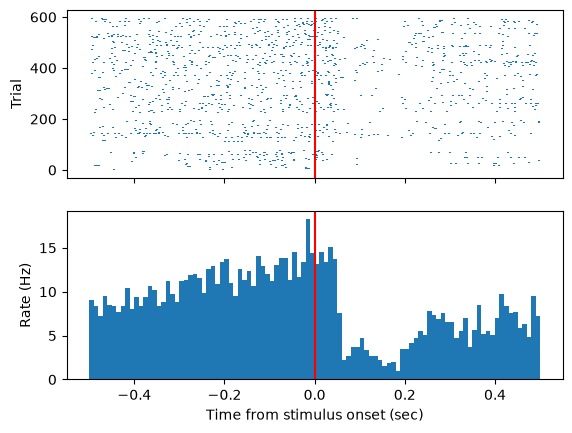

In [11]:
# Overall raster and PSTH
gratings_nonblank = gratings[gratings["is_blank"] == False]

print("Total presentations:", len(gratings))
print("Nonblank presentations:", len(gratings_nonblank))
print("Blank presentations:", gratings["is_blank"].sum())

# Align spikes to stimulus onset

events = gratings_nonblank["start_time"].to_numpy()

def align(st, events, win):
    rel = [st[np.abs(st-event) < win] - event for event in events]
    return rel

rel = align(st, events, 0.5)

def psth(rel, win, w):
    bins = np.arange(-win, win+w, w)
    counts, edges = np.histogram(np.concatenate(rel), bins=bins)
    return edges, counts / w / len(rel)

# Plot raster and PSTH

edges, h = psth(rel, 0.5, 0.01)

fig, ax = plt.subplots(2, 1, sharex=True)

ax[0].eventplot(rel)
ax[0].axvline(0, color="red")
ax[0].set_ylabel("Trial")

ax[1].bar(edges[:-1]+0.005, h, width=0.01)
ax[1].axvline(0, color="red")
ax[1].set_xlabel("Time from stimulus onset (sec)")
ax[1].set_ylabel("Rate (Hz)")

plt.show()

To examine orientation-dependent responses, I calculated the mean firing rate during the first 250 ms after stimulus onset for each orientation. The results ranged from 3.73 Hz to 7.25 Hz. The highest mean firing rate occurred at 180° (7.25 Hz), while the lowest occurred at 315° (3.73 Hz). These differences suggest that the neuron may respond differently to different stimulus orientations. However, this is only a descriptive observation from one neuron, and further analysis is needed to determine whether these differences are consistent across trials and neurons.

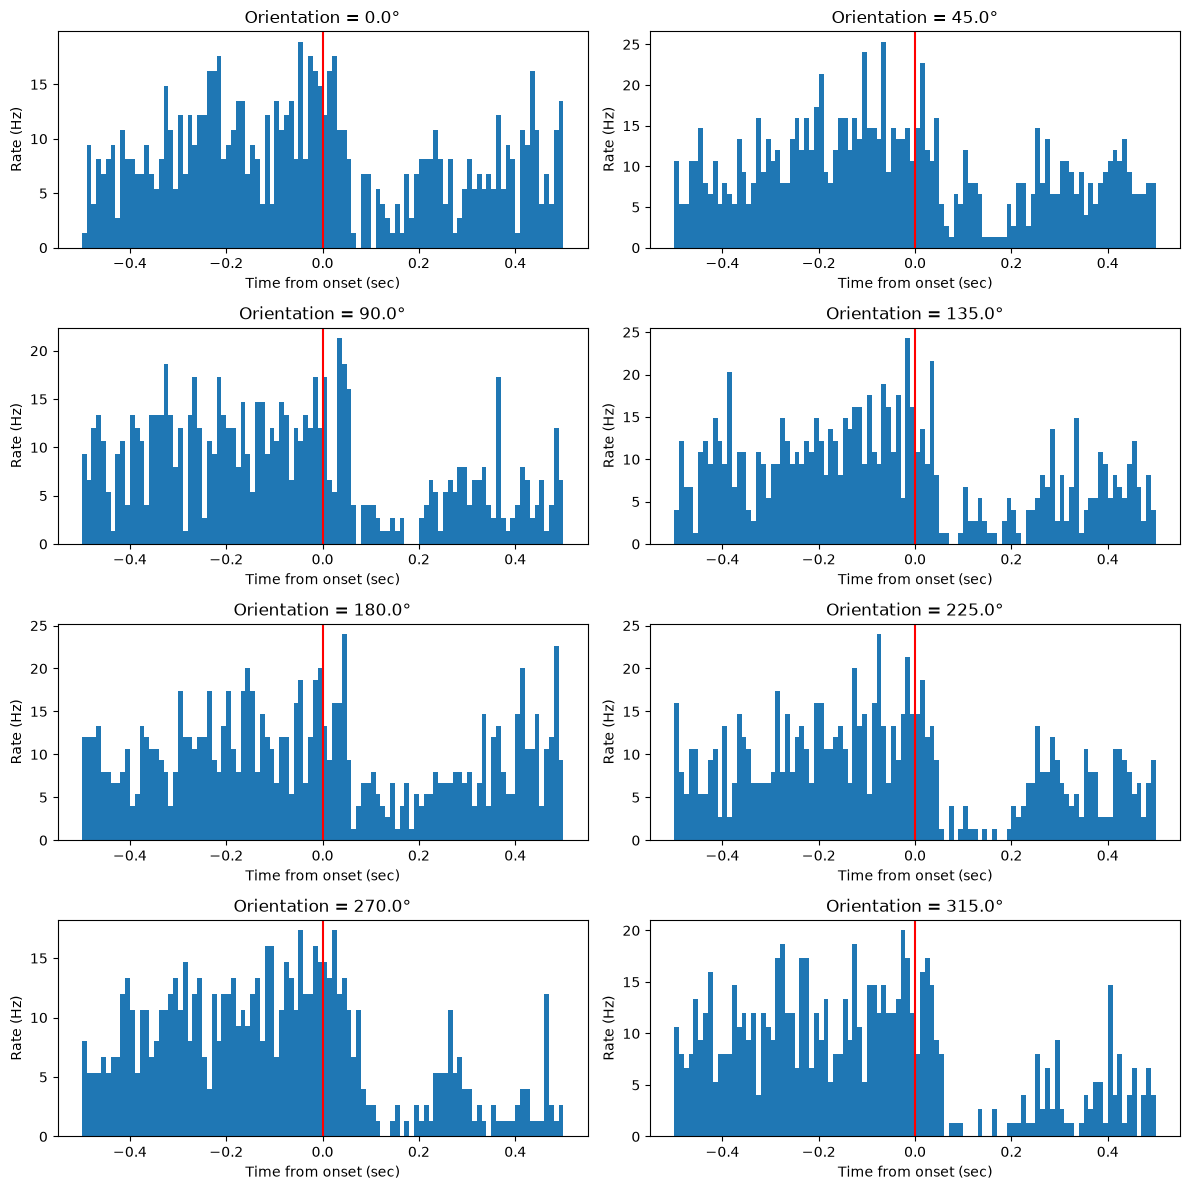

   Orientation  Firing rate (Hz)
0          0.0          6.756757
1         45.0          6.880000
2         90.0          5.333333
3        135.0          4.486486
4        180.0          7.253333
5        225.0          4.373333
6        270.0          5.333333
7        315.0          3.733333


In [12]:
# Plot all 8 directions's PSTH with 10ms bin

orientations = sorted(gratings_nonblank["orientation"].unique())

fig, axes = plt.subplots(4, 2, figsize=(12, 12))
axes = axes.flatten()

for i, direction in enumerate(orientations):

    events = gratings_nonblank.loc[
        gratings_nonblank["orientation"] == direction,
        "start_time"
    ].to_numpy()

    rel = align(st, events, 0.5)
    edges, h = psth(rel, 0.5, 0.01)

    axes[i].bar(edges[:-1] + 0.005, h, width=0.01)
    axes[i].axvline(0, color="red")
    axes[i].set_title(f"Orientation = {direction}°")
    axes[i].set_ylabel("Rate (Hz)")
    axes[i].set_xlabel("Time from onset (sec)")

plt.tight_layout()
plt.show()


# Calculate firing rate for each orientation

orientation_rates = []

for direction in orientations:

    events = gratings_nonblank.loc[gratings_nonblank["orientation"] == direction, "start_time"].to_numpy()

    rel = align(st, events, 0.5)

    rates = [np.sum((r >= 0) & (r < 0.25)) / 0.25 for r in rel]

    orientation_rates.append([direction, np.mean(rates)])

rate_table = pd.DataFrame(
    orientation_rates,
    columns=["Orientation", "Firing rate (Hz)"]
)

print(rate_table)